In [ ]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

SEED = 328                     
RESULTS = {}
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

In [2]:
COLS = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship",
        "race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
URLS = ["https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
        "https://github.com/shap/shap/raw/master/data/adult.data"]
raw = None
for u in URLS:
    try:
        raw = pd.read_csv(u, names=COLS, skipinitialspace=True, na_values="?")
        print("loaded from", u); break
    except Exception as e:
        print("failed:", u, type(e).__name__)
assert raw is not None and raw.shape == (32561, 15), raw.shape
print(raw.shape); raw.head()

failed: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data URLError


loaded from https://github.com/shap/shap/raw/master/data/adult.data
(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df = raw.copy()
miss = raw.replace("?", np.nan).isna().sum()
RESULTS["n_rows"] = int(len(df)); RESULTS["missing"] = {k:int(v) for k,v in miss[miss>0].items()}
RESULTS["n_duplicates"] = int(df.duplicated().sum())
print("Missing values:\n", miss[miss>0]); print("Duplicates:", RESULTS["n_duplicates"])

for c in ["workclass","occupation","native_country"]:
    df[c] = df[c].fillna("Unknown")
# tiny categories cause (quasi-)perfect separation in logistic regression -> merge them
df["workclass"] = df["workclass"].replace({"Never-worked":"Unknown","Without-pay":"Unknown"})   # 21 rows, 0 high earners
df["occupation"] = df["occupation"].replace({"Armed-Forces":"Protective-serv"})                  # 9 rows
df["y"] = (df["income"] == ">50K").astype(int)
RESULTS["base_rate"] = float(df.y.mean())

def build_raw_features(d):
    X = pd.DataFrame(index=d.index)
    X["age"] = d.age
    X["education_num"] = d.education_num
    X["hours_per_week"] = d.hours_per_week
    X["capital_gain_log"] = np.log1p(d.capital_gain)
    X["capital_loss_log"] = np.log1p(d.capital_loss)
    X["sex_Male"] = (d.sex == "Male").astype(int)
    X["married_civ_spouse"] = (d.marital_status == "Married-civ-spouse").astype(int)
    for lvl in ["Black","Asian-Pac-Islander","Amer-Indian-Eskimo","Other"]:
        X["race_"+lvl] = (d.race == lvl).astype(int)
    for lvl in sorted(d.workclass.unique()):
        if lvl not in ("Private","Unknown"): X["wc_"+lvl] = (d.workclass == lvl).astype(int)   # Unknown handled by occ_Unknown
    for lvl in sorted(d.occupation.unique()):
        if lvl != "Adm-clerical": X["occ_"+lvl] = (d.occupation == lvl).astype(int)
    X["native_nonUS"] = ((d.native_country != "United-States") & (d.native_country != "Unknown")).astype(int)
    X["native_Unknown"] = (d.native_country == "Unknown").astype(int)
    return X

CONT = ["age","education_num","hours_per_week","capital_gain_log","capital_loss_log"]
class Prep:
    """winsorise (age, hours) + z-score continuous columns using statistics from the fitting data only"""
    def fit(self, X):
        self.lo = X[["age","hours_per_week"]].quantile(0.01); self.hi = X[["age","hours_per_week"]].quantile(0.99)
        Xw = self._wins(X); self.mu = Xw[CONT].mean(); self.sd = Xw[CONT].std(); return self
    def _wins(self, X):
        X = X.copy()
        for c in ["age","hours_per_week"]: X[c] = X[c].clip(self.lo[c], self.hi[c])
        return X
    def transform(self, X):
        X = self._wins(X); X[CONT] = (X[CONT]-self.mu)/self.sd
        return sm.add_constant(X.astype(float), has_constant="add")

Xraw = build_raw_features(df); y = df["y"]
Xraw_tr, Xraw_te, ytr, yte = train_test_split(Xraw, y, test_size=0.30, random_state=SEED)
prep = Prep().fit(Xraw_tr)
Xtr, Xte = prep.transform(Xraw_tr), prep.transform(Xraw_te)
RESULTS.update(n_train=int(len(Xtr)), n_test=int(len(Xte)), n_features=int(Xtr.shape[1]-1),
               train_rate=float(ytr.mean()), test_rate=float(yte.mean()))
# outlier documentation
RESULTS["outliers"] = {
  "capital_gain_nonzero": int((df.capital_gain>0).sum()), "capital_gain_99999": int((df.capital_gain==99999).sum()),
  "capital_loss_nonzero": int((df.capital_loss>0).sum()),
  "age_clipped": [float(prep.lo["age"]), float(prep.hi["age"])],
  "hours_clipped": [float(prep.lo["hours_per_week"]), float(prep.hi["hours_per_week"])],
  "age_rows_clipped": int(((Xraw_tr.age<prep.lo["age"])|(Xraw_tr.age>prep.hi["age"])).sum()),
  "hours_rows_clipped": int(((Xraw_tr.hours_per_week<prep.lo["hours_per_week"])|(Xraw_tr.hours_per_week>prep.hi["hours_per_week"])).sum())}
print(RESULTS["n_train"], RESULTS["n_test"], RESULTS["n_features"], round(RESULTS["base_rate"],4)); print(RESULTS["outliers"])

Missing values:
 workclass         1836
occupation        1843
native_country     583
dtype: int64
Duplicates: 24


22792 9769 31 0.2408
{'capital_gain_nonzero': 2712, 'capital_gain_99999': 159, 'capital_loss_nonzero': 1519, 'age_clipped': [17.0, 74.0], 'hours_clipped': [8.0, 80.0], 'age_rows_clipped': 201, 'hours_rows_clipped': 361}


In [ ]:
ols = sm.OLS(ytr, Xtr).fit()
logit = sm.Logit(ytr, Xtr).fit(method="newton", maxiter=100, disp=0)
print("logit converged:", logit.mle_retvals["converged"])
pA = ols.predict(Xte); pB = logit.predict(Xte)
med = float(np.median(pA))
highA = (pA >= med).astype(int); highB = (pB >= 0.5).astype(int)
ct = pd.crosstab(highA.rename("A: OLS ≥ median"), highB.rename("B: Logit ≥ 0.5"))
ct = ct.reindex(index=[0,1], columns=[0,1], fill_value=0)
mism = int((highA != highB).sum()); n_te = len(yte)
acc = lambda h: float((h.values == yte.values).mean())
RESULTS["part1"] = dict(
  ols_r2=float(ols.rsquared), ols_pred_min=float(pA.min()), ols_pred_max=float(pA.max()),
  ols_n_below0=int((pA<0).sum()), ols_n_above1=int((pA>1).sum()), median_pred=med,
  ols_mean_pred=float(pA.mean()), cm=ct.values.tolist(),
  both_low=int(ct.loc[0,0]), A_low_B_high=int(ct.loc[0,1]), A_high_B_low=int(ct.loc[1,0]), both_high=int(ct.loc[1,1]),
  mismatch=mism, mismatch_pct=100*mism/n_te, n_test=int(n_te),
  flaggedA=int(highA.sum()), flaggedB=int(highB.sum()), flaggedA_pct=100*float(highA.mean()), flaggedB_pct=100*float(highB.mean()),
  accA=acc(highA), accB=acc(highB), logit_pred_median=float(np.median(pB)), logit_pred_mean=float(pB.mean()),
  pseudo_r2=float(logit.prsquared), test_pos_rate=float(yte.mean()),
  ols_quantile_at_base=float(np.quantile(pA, 1-yte.mean())))
thrA2 = RESULTS["part1"]["ols_quantile_at_base"]; highA2 = (pA>=thrA2).astype(int)
RESULTS["part1"]["mismatch_if_base_rate_threshold"] = int((highA2!=highB).sum())
RESULTS["part1"]["mismatch_if_base_rate_threshold_pct"] = 100*float((highA2!=highB).mean())
RESULTS["part1"]["accA2"] = acc(highA2)
print(ct); print({k:v for k,v in RESULTS["part1"].items() if k!="cm"})

logit converged: True
B: Logit ≥ 0.5      0     1
A: OLS ≥ median            
0                4884     0
1                2968  1917
{'ols_r2': 0.3681222389829778, 'ols_pred_min': -0.36386871076864474, 'ols_pred_max': 1.2124424535117537, 'ols_n_below0': 2101, 'ols_n_above1': 42, 'median_pred': 0.22153746019301473, 'ols_mean_pred': 0.2388700189936267, 'both_low': 4884, 'A_low_B_high': 0, 'A_high_B_low': 2968, 'both_high': 1917, 'mismatch': 2968, 'mismatch_pct': 30.38182004299314, 'n_test': 9769, 'flaggedA': 4885, 'flaggedB': 1917, 'flaggedA_pct': 50.00511823113932, 'flaggedB_pct': 19.623298188146176, 'accA': 0.7131743269526052, 'accB': 0.8507523799774798, 'logit_pred_median': 0.10543823893547243, 'logit_pred_mean': 0.23968944511091236, 'pseudo_r2': 0.3882986641686039, 'test_pos_rate': 0.23963558194288054, 'ols_quantile_at_base': 0.4222335477241835, 'mismatch_if_base_rate_threshold': 458, 'mismatch_if_base_rate_threshold_pct': 4.688299723615518, 'accA2': 0.8415395639267069}


In [5]:
def fit_logit_generic(Xr, yy):
    Z = Xr.copy().astype(float)
    for c in CONT:
        if c in Z and Z[c].std() > 0: Z[c] = (Z[c]-Z[c].mean())/Z[c].std()
    Z = sm.add_constant(Z, has_constant="add")
    Z = Z.loc[:, [c for c in Z if c=="const" or Z[c].std() > 0]]
    return sm.Logit(yy, Z).fit(method="lbfgs", maxiter=2000, disp=0)

feat_noM = [c for c in Xraw.columns if c != "married_civ_spouse"]
mask = Xraw.married_civ_spouse == 1
m_full = fit_logit_generic(Xraw[feat_noM], y)
m_A    = fit_logit_generic(Xraw.loc[mask, feat_noM], y[mask])
m_B    = fit_logit_generic(Xraw.loc[~mask, feat_noM], y[~mask])
m_full_with = fit_logit_generic(Xraw, y)
def coef_row(m, name):
    b = m.params[name]; lo, hi = m.conf_int().loc[name]
    return dict(coef=float(b), se=float(m.bse[name]), ci_lo=float(lo), ci_hi=float(hi), p=float(m.pvalues[name]), odds_ratio=float(np.exp(b)))
simp = {}
for name in ["sex_Male","education_num","hours_per_week","age"]:
    simp[name] = dict(full=coef_row(m_full,name), A=coef_row(m_A,name), B=coef_row(m_B,name))
    d = simp[name]["A"]["coef"]-simp[name]["B"]["coef"]; se = np.hypot(simp[name]["A"]["se"], simp[name]["B"]["se"])
    simp[name]["z_A_vs_B"] = float(d/se)
RESULTS["simpson"] = dict(n_A=int(mask.sum()), n_B=int((~mask).sum()), rate_A=float(y[mask].mean()), rate_B=float(y[~mask].mean()),
    rate_male=float(y[Xraw.sex_Male==1].mean()), rate_female=float(y[Xraw.sex_Male==0].mean()),
    male_share_A=float(Xraw.loc[mask,"sex_Male"].mean()), male_share_B=float(Xraw.loc[~mask,"sex_Male"].mean()),
    married_share_male=float(Xraw.loc[Xraw.sex_Male==1,"married_civ_spouse"].mean()), married_share_female=float(Xraw.loc[Xraw.sex_Male==0,"married_civ_spouse"].mean()),
    coefs=simp, sex_full_with_married=coef_row(m_full_with,"sex_Male"))
pd.DataFrame({k:{**{f"{g}_{kk}":v[g][kk] for g in ["full","A","B"] for kk in ["coef","ci_lo","ci_hi","p"]}} for k,v in simp.items()}).T.round(3)

,full_coef,full_ci_lo,full_ci_hi,full_p,A_coef,A_ci_lo,A_ci_hi,A_p,B_coef,B_ci_lo,B_ci_hi,B_p
sex_Male,1.138,1.055,1.220,0.0,-0.370,-0.502,-0.238,0.0,0.724,0.566,0.881,0.0
education_num,0.669,0.627,0.710,0.0,0.749,0.695,0.802,0.0,0.763,0.669,0.857,0.0
hours_per_week,0.381,0.346,0.416,0.0,0.325,0.283,0.368,0.0,0.501,0.428,0.574,0.0
age,0.575,0.539,0.610,0.0,0.291,0.249,0.333,0.0,0.658,0.582,0.735,0.0


In [6]:
DROP = "education_num"
full = logit
red  = sm.Logit(ytr, Xtr.drop(columns=[DROP])).fit(method="newton", maxiter=100, disp=0)
chk = ["age","hours_per_week","capital_gain_log","sex_Male","married_civ_spouse","race_Black","native_nonUS","occ_Prof-specialty","occ_Exec-managerial"]
ovb = pd.DataFrame({"full":full.params[chk], "reduced":red.params[chk]})
ovb["abs_change"] = ovb.reduced-ovb.full; ovb["pct"] = 100*ovb.abs_change/ovb.full.abs()
RESULTS["ovb"] = dict(dropped=DROP, table={k:{c:float(v) for c,v in r.items()} for k,r in ovb.iterrows()},
    most_shifted=ovb.pct.abs().idxmax(), llf_full=float(full.llf), llf_red=float(red.llf),
    lr_stat=float(2*(full.llf-red.llf)), full_coef_education=float(full.params[DROP]), full_p_education=float(full.pvalues[DROP]))
ovb.round(3)

,full,reduced,abs_change,pct
age,0.408,0.359,-0.049,-12.079
hours_per_week,0.417,0.443,0.026,6.150
capital_gain_log,0.512,0.519,0.007,1.447
sex_Male,0.153,0.227,0.074,48.753
married_civ_spouse,2.307,2.231,-0.076,-3.288
race_Black,-0.091,-0.157,-0.066,-73.395
native_nonUS,-0.203,-0.310,-0.106,-52.344
occ_Prof-specialty,0.586,1.269,0.683,116.599
occ_Exec-managerial,0.809,1.086,0.277,34.305


In [7]:
te = Xraw_te.copy(); te["y"] = yte.values; te["p"] = pB.values
fp_m = (te.p >= 0.75) & (te.y == 0); fn_m = (te.p <= 0.25) & (te.y == 1); wrong = fp_m | fn_m
W = te[wrong]; S = W.sample(50, random_state=SEED) if len(W) > 50 else W
te["no_capital"] = ((te.capital_gain_log==0)&(te.capital_loss_log==0)).astype(int)
te["edu_lt13"]   = (te.education_num < 13).astype(int)
te["misfire"] = (((te.married_civ_spouse==1)&(te.y==0)&(te.p>=.75)) | ((te.married_civ_spouse==0)&(te.y==1)&(te.p<=.25))).astype(int)
S = te.loc[S.index]
def prof(d):
    return dict(n=int(len(d)), age_mean=float(d.age.mean()), age_median=float(d.age.median()), male=float(d.sex_Male.mean()), married=float(d.married_civ_spouse.mean()),
                black=float(d.race_Black.mean()), edu_mean=float(d.education_num.mean()), hours_mean=float(d.hours_per_week.mean()),
                no_capital=float(d.no_capital.mean()), edu_lt13=float(d.edu_lt13.mean()), prof_exec=float(((d["occ_Prof-specialty"]+d["occ_Exec-managerial"])>0).mean()))
RESULTS["adv"] = dict(n_fp=int(fp_m.sum()), n_fn=int(fn_m.sum()), n_wrong=int(wrong.sum()), pct_wrong=100*float(wrong.mean()),
    n_conf=int(((te.p>=.75)|(te.p<=.25)).sum()), n_hi=int((te.p>=.75).sum()), n_lo=int((te.p<=.25).sum()),
    sample_n=int(len(S)), sample_fn=int((S.y==1).sum()), sample_fp=int((S.y==0).sum()),
    profile_sample=prof(S), profile_test=prof(te), profile_fn_all=prof(te[fn_m]), profile_fp_all=prof(te[fp_m]),
    misfire_sample=float(S.misfire.mean()), misfire_all=float(te[wrong].misfire.mean()),
    fn_unmarried_share=float((te[fn_m].married_civ_spouse==0).mean()), fp_married_share=float(te[fp_m].married_civ_spouse.mean()),
    fn_mean_p=float(te[fn_m].p.mean()), fp_mean_p=float(te[fp_m].p.mean()))
# does an interaction term fix it? (married x sex, married x age, married x education)
def add_int(X):
    X = X.copy(); X["m_x_male"]=X.married_civ_spouse*X.sex_Male; X["m_x_age"]=X.married_civ_spouse*X.age; X["m_x_edu"]=X.married_civ_spouse*X.education_num; return X
lg_int = sm.Logit(ytr, add_int(Xtr)).fit(method="newton", maxiter=100, disp=0)
p_int = lg_int.predict(add_int(Xte)); w_int = ((p_int>=.75)&(yte==0))|((p_int<=.25)&(yte==1))
RESULTS["adv"].update(n_wrong_with_interactions=int(w_int.sum()), llf_base=float(logit.llf), llf_int=float(lg_int.llf),
    int_coefs={k:float(lg_int.params[k]) for k in ["married_civ_spouse","m_x_male","m_x_age","m_x_edu"]},
    int_p={k:float(lg_int.pvalues[k]) for k in ["m_x_male","m_x_age","m_x_edu"]}, coef_married=float(logit.params["married_civ_spouse"]),
    coef_capgain=float(logit.params["capital_gain_log"]))
print({k:v for k,v in RESULTS["adv"].items() if not k.startswith("profile")})
pd.DataFrame({"adversarial_50":prof(S),"test_set":prof(te)}).round(3)

{'n_fp': 115, 'n_fn': 412, 'n_wrong': 527, 'pct_wrong': 5.394615620841437, 'n_conf': 7259, 'n_hi': 850, 'n_lo': 6409, 'sample_n': 50, 'sample_fn': 41, 'sample_fp': 9, 'misfire_sample': 0.54, 'misfire_all': 0.6204933586337761, 'fn_unmarried_share': 0.5169902912621359, 'fp_married_share': 0.991304347826087, 'fn_mean_p': 0.14835698506118922, 'fp_mean_p': 0.8371826735798615, 'n_wrong_with_interactions': 502, 'llf_base': -7704.130193047893, 'llf_int': -7609.235300356651, 'int_coefs': {'married_civ_spouse': 3.428057810908557, 'm_x_male': -1.4266330776845446, 'm_x_age': -0.3260668946465655, 'm_x_edu': -0.1218004160949919}, 'int_p': {'m_x_male': 1.6839784886204333e-34, 'm_x_age': 4.4679921547494836e-10, 'm_x_edu': 0.02985340731340315}, 'coef_married': 2.3065660628170486, 'coef_capgain': 0.5117847006429537}


,adversarial_50,test_set
n,50.00,9769.000
age_mean,42.42,38.552
age_median,42.00,37.000
male,0.70,0.667
married,0.64,0.452
black,0.04,0.092
edu_mean,10.70,10.114
hours_mean,42.04,40.363
no_capital,0.86,0.873
edu_lt13,0.62,0.749


In [8]:
sexM = Xraw_te.sex_Male.values; A = sexM == 0; B = sexM == 1; yt = yte.values; pt = pB.values
def ratio(a, b): return float(a/b) if b > 0 else float("nan")
rows = []
for t in np.round(np.arange(0.05, 0.96, 0.10), 2):
    yh = (pt >= t).astype(int)
    def stats(g):
        pos = yh[g].mean(); tpr = yh[g & (yt==1)].mean(); fpr = yh[g & (yt==0)].mean()
        ppv = yt[g & (yh==1)].mean() if (g & (yh==1)).sum() > 0 else float("nan")
        return pos, tpr, fpr, ppv, int((g & (yh==1)).sum())
    pa,ta,fa,va,na_ = stats(A); pb,tb,fb,vb,nb_ = stats(B)
    dp = ratio(pa,pb); eo = np.nanmin([ratio(ta,tb), ratio(fa,fb)]) if not (np.isnan(ratio(ta,tb)) and np.isnan(ratio(fa,fb))) else float("nan")
    pp = ratio(va,vb) if not (np.isnan(va) or np.isnan(vb)) else float("nan")
    rows.append(dict(t=float(t), pos_A=pa, pos_B=pb, TPR_A=ta, TPR_B=tb, FPR_A=fa, FPR_B=fb, PPV_A=va, PPV_B=vb, nflag_A=na_, nflag_B=nb_,
                     DP=dp, EO=float(eo), PP=pp, acc=float((yh==yt).mean())))
fair = pd.DataFrame(rows)
RESULTS["fair"] = dict(rows=fair.to_dict("records"), n_A=int(A.sum()), n_B=int(B.sum()),
                       base_A=float(yt[A].mean()), base_B=float(yt[B].mean()))
fair.round(3)

,t,pos_A,pos_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B,nflag_A,nflag_B,DP,EO,PP,acc
0,0.05,0.399,0.716,0.938,0.987,0.329,0.598,0.269,0.417,1299,4661,0.557,0.550,0.647,0.620
1,0.15,0.193,0.565,0.775,0.944,0.118,0.401,0.459,0.505,630,3680,0.342,0.295,0.909,0.759
2,0.25,0.122,0.455,0.627,0.861,0.057,0.279,0.589,0.572,397,2963,0.268,0.203,1.030,0.811
3,0.35,0.089,0.364,0.515,0.770,0.034,0.189,0.664,0.639,289,2372,0.244,0.178,1.040,0.837
4,0.45,0.065,0.298,0.421,0.690,0.019,0.128,0.744,0.699,211,1941,0.217,0.146,1.064,0.850
5,0.55,0.048,0.237,0.330,0.586,0.011,0.086,0.788,0.747,156,1544,0.202,0.133,1.055,0.848
6,0.65,0.030,0.181,0.223,0.478,0.005,0.052,0.856,0.799,97,1177,0.165,0.094,1.070,0.840
7,0.75,0.016,0.122,0.131,0.349,0.001,0.024,0.925,0.861,53,797,0.133,0.057,1.074,0.824
8,0.85,0.010,0.068,0.080,0.203,0.001,0.009,0.909,0.907,33,440,0.150,0.115,1.003,0.800
9,0.95,0.002,0.024,0.013,0.077,0.000,0.001,1.000,0.968,5,157,0.064,0.000,1.033,0.776


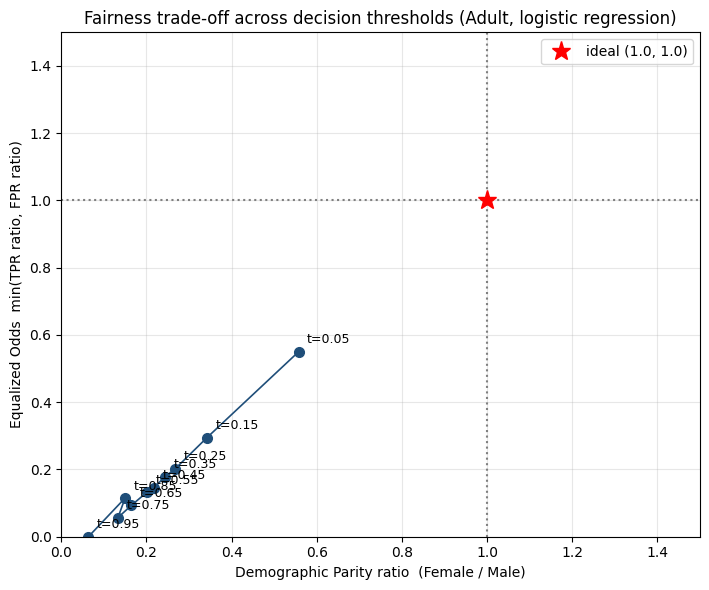

In [9]:
ok = fair.dropna(subset=["DP","EO"])
fig, ax = plt.subplots(figsize=(7.2,6))
ax.plot(ok.DP, ok.EO, "-o", color="#1f4e79", lw=1.2, ms=7)
for _, r in ok.iterrows(): ax.annotate(f"t={r.t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(6,6), fontsize=9)
ax.axvline(1, ls=":", c="grey"); ax.axhline(1, ls=":", c="grey"); ax.plot([1],[1],"*",c="red",ms=14,label="ideal (1.0, 1.0)")
ax.set_xlim(0,1.5); ax.set_ylim(0,1.5); ax.set_xlabel("Demographic Parity ratio  (Female / Male)"); ax.set_ylabel("Equalized Odds  min(TPR ratio, FPR ratio)")
ax.set_title("Fairness trade-off across decision thresholds (Adult, logistic regression)"); ax.legend(loc="upper right"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fairness_tradeoff.png", dpi=170); plt.show()

In [10]:
ok = fair.dropna(subset=["DP","EO","PP"]).copy()
t_dp = float(ok.loc[(ok.DP-1).abs().idxmin(),"t"]); t_eo = float(ok.loc[(ok.EO-1).abs().idxmin(),"t"])
t_lo = float(ok.t.min()); t_pp = float(ok[(ok.PP-1).abs() <= 0.05].t.min())
r0, r1 = ok[ok.t==t_lo].iloc[0], ok[ok.t==t_pp].iloc[0]
pct = lambda a,b: 100*(b-a)/abs(a)
RESULTS["tradeoff"] = dict(t_dp=t_dp, t_eo=t_eo, t_lo=t_lo, t_pp=t_pp,
    DP0=float(r0.DP), EO0=float(r0.EO), PP0=float(r0.PP), DP1=float(r1.DP), EO1=float(r1.EO), PP1=float(r1.PP),
    PP_gain_pct=pct(r0.PP,r1.PP), DP_loss_pct=-pct(r0.DP,r1.DP), EO_loss_pct=-pct(r0.EO,r1.EO),
    cost_DP_per_PP=-pct(r0.DP,r1.DP)/pct(r0.PP,r1.PP), cost_EO_per_PP=-pct(r0.EO,r1.EO)/pct(r0.PP,r1.PP),
    base_rate_ratio_test=float(yt[A].mean()/yt[B].mean()))
print(RESULTS["tradeoff"])

{'t_dp': 0.05, 't_eo': 0.05, 't_lo': 0.05, 't_pp': 0.25, 'DP0': 0.5574767122450024, 'EO0': 0.5502325141726295, 'PP0': 0.6466790187175591, 'DP1': 0.26801280079207856, 'EO1': 0.20265512724980878, 'PP1': 1.0303559884978044, 'PP_gain_pct': np.float64(59.33035689655157), 'DP_loss_pct': np.float64(51.9239467936212), 'EO_loss_pct': np.float64(63.1691835669624), 'cost_DP_per_PP': np.float64(0.8751666012081439), 'cost_EO_per_PP': np.float64(1.064702571688625), 'base_rate_ratio_test': 0.37912325088392157}


In [11]:
T2 = Xraw_te.copy(); T2["y"] = yte.values; T2["p"] = pB.values
band = T2[(T2.sex_Male==0)&(T2.y==1)&(T2.p>=0.25)&(T2.p<0.35)]
w = band.iloc[(band.p-band.p.median()).abs().argsort().iloc[0]]
men = T2[(T2.sex_Male==1)&(T2.y==1)]
sd = T2[["age","education_num","hours_per_week"]].std()
dist = (((men[["age","education_num","hours_per_week"]]-w[["age","education_num","hours_per_week"]])/sd)**2).sum(axis=1)
m = men.loc[dist.idxmin()]
raw_w, raw_m = df.loc[w.name], df.loc[m.name]
def person(r, p): return dict(age=int(r.age), education_num=int(r.education_num), hours=int(r.hours_per_week), marital=r.marital_status,
                              occupation=r.occupation, capital_gain=int(r.capital_gain), p=float(p))
RESULTS["case"] = dict(woman=person(raw_w, w.p), man=person(raw_m, m.p))
print(RESULTS["case"])

{'woman': {'age': 49, 'education_num': 13, 'hours': 56, 'marital': 'Never-married', 'occupation': 'Exec-managerial', 'capital_gain': 0, 'p': 0.29206014253657064}, 'man': {'age': 48, 'education_num': 13, 'hours': 55, 'marital': 'Married-civ-spouse', 'occupation': 'Unknown', 'capital_gain': 0, 'p': 0.5244864245000146}}


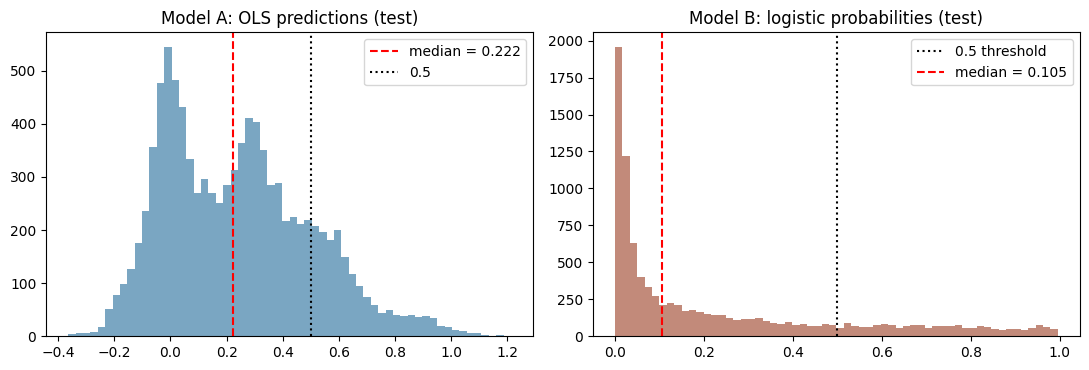

saved results.json


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(pA, bins=60, color="#7aa6c2"); ax[0].axvline(med, c="red", ls="--", label=f"median = {med:.3f}"); ax[0].axvline(0.5, c="k", ls=":", label="0.5")
ax[0].set_title("Model A: OLS predictions (test)"); ax[0].legend()
ax[1].hist(pB, bins=60, color="#c28a7a"); ax[1].axvline(0.5, c="k", ls=":", label="0.5 threshold"); ax[1].axvline(np.median(pB), c="red", ls="--", label=f"median = {np.median(pB):.3f}")
ax[1].set_title("Model B: logistic probabilities (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig("part1_scores.png", dpi=170); plt.show()
json.dump(RESULTS, open("results.json","w"), indent=1, default=float)
print("saved results.json")